# Model Selection and Hyperparameter Tuning

**Use scikit-learn as much as possible!**

In [1]:
import numpy as np
import pandas as pd

## Ames Housing Data

As usual, we'll try to predict SalePrice using a mix of quantitative and categorical features. See the [data documentation](https://jse.amstat.org/v19n3/decock/DataDocumentation.txt) for all the variables that are available in the data set. We'll try to come up with a model that minimizes test error, measured by root mean square error (RMSE).

In [2]:
df_ames = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/main/data/AmesHousing.txt", sep="\t")
print(df_ames.head().to_string())

   Order        PID  MS SubClass MS Zoning  Lot Frontage  Lot Area Street Alley Lot Shape Land Contour Utilities Lot Config Land Slope Neighborhood Condition 1 Condition 2 Bldg Type House Style  Overall Qual  Overall Cond  Year Built  Year Remod/Add Roof Style Roof Matl Exterior 1st Exterior 2nd Mas Vnr Type  Mas Vnr Area Exter Qual Exter Cond Foundation Bsmt Qual Bsmt Cond Bsmt Exposure BsmtFin Type 1  BsmtFin SF 1 BsmtFin Type 2  BsmtFin SF 2  Bsmt Unf SF  Total Bsmt SF Heating Heating QC Central Air Electrical  1st Flr SF  2nd Flr SF  Low Qual Fin SF  Gr Liv Area  Bsmt Full Bath  Bsmt Half Bath  Full Bath  Half Bath  Bedroom AbvGr  Kitchen AbvGr Kitchen Qual  TotRms AbvGrd Functional  Fireplaces Fireplace Qu Garage Type  Garage Yr Blt Garage Finish  Garage Cars  Garage Area Garage Qual Garage Cond Paved Drive  Wood Deck SF  Open Porch SF  Enclosed Porch  3Ssn Porch  Screen Porch  Pool Area Pool QC  Fence Misc Feature  Misc Val  Mo Sold  Yr Sold Sale Type Sale Condition  SalePrice
0 

In [3]:
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def make_model(regressor):
    numeric = Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ])
    categorical = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore'))
    ])
    preprocess = ColumnTransformer([
        ('numeric', numeric, make_column_selector(dtype_include=np.number)),
        ('categorical', categorical, make_column_selector(dtype_exclude=np.number))
    ])
    return Pipeline([('preprocess', preprocess), ('model', regressor)])

cv = KFold(n_splits=5, shuffle=True, random_state=5544)
ames_train, ames_test = train_test_split(df_ames, test_size=0.20, random_state=5544)
y_train = ames_train['SalePrice']
y_test = ames_test['SalePrice']

1\. Recall that in a previous notebook we fit a 10-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. But what about other sets of features?

Specify 5 sets of features to investigate. These sets could be subsets of the variables above, but you should also include other variables from the data set. The choice is up to you, but try to guess which sets might lead to good models based on your intuition and what we have already seen for this data set.

For each set of features, fit a 10-nearest neighbors regression model and estimate its test error (RMSE) using cross-validation. You can write a loop to iterate over the sets of features similar to what was done in the Model Selection section of the pre-class notebook.

Report your lowest RMSE and the corresponding features.

In [4]:
feature_sets = {
    'Original': ['Gr Liv Area', 'Bedroom AbvGr', 'Full Bath', 'Half Bath', 'Neighborhood'],
    'Size and quality': ['Gr Liv Area', 'Overall Qual', 'Neighborhood'],
    'Size, quality, age': ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Neighborhood'],
    'Size, quality, garage': ['Gr Liv Area', 'Overall Qual', 'Garage Cars', 'Total Bsmt SF', 'Neighborhood'],
    'Expanded': ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Year Remod/Add', 'Garage Cars', 'Total Bsmt SF', 'Full Bath', 'Neighborhood', 'Kitchen Qual']
}
rows = []
for name, features in feature_sets.items():
    model = make_model(KNeighborsRegressor(n_neighbors=10))
    scores = cross_val_score(model, ames_train[features], y_train, cv=cv, scoring='neg_root_mean_squared_error')
    rows.append({'Feature set': name, 'CV RMSE': -scores.mean()})
part1 = pd.DataFrame(rows).sort_values('CV RMSE')
print((part1).to_string())
best_set_part1 = part1.iloc[0]['Feature set']
print('Best feature set:', best_set_part1)
print('Features:', feature_sets[best_set_part1])
print(f"Lowest CV RMSE: ${part1.iloc[0]['CV RMSE']:,.2f}")

             Feature set       CV RMSE
4               Expanded  29469.717145
3  Size, quality, garage  30542.015785
2     Size, quality, age  33088.381213
1       Size and quality  33494.875376
0               Original  40267.922372
Best feature set: Expanded
Features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Year Remod/Add', 'Garage Cars', 'Total Bsmt SF', 'Full Bath', 'Neighborhood', 'Kitchen Qual']
Lowest CV RMSE: $29,469.72


2\. Recall that in a previous notebook we fit a $k$-nearest neighbors regression model that predicts the price (just **SalePrice**, not log) of a home using square footage (**Gr Liv Area**), number of bedrooms (**Bedroom AbvGr**), number of full bathrooms (**Full Bath**), number of half bathrooms (**Half Bath**), and **Neighborhood**. Previously we used a loop to iterate and find the value of $k$ with the smallest test error (RMSE).

Now use grid search in scikit-learn to implement this process. Use the results to create a plot of test error versus $k$.

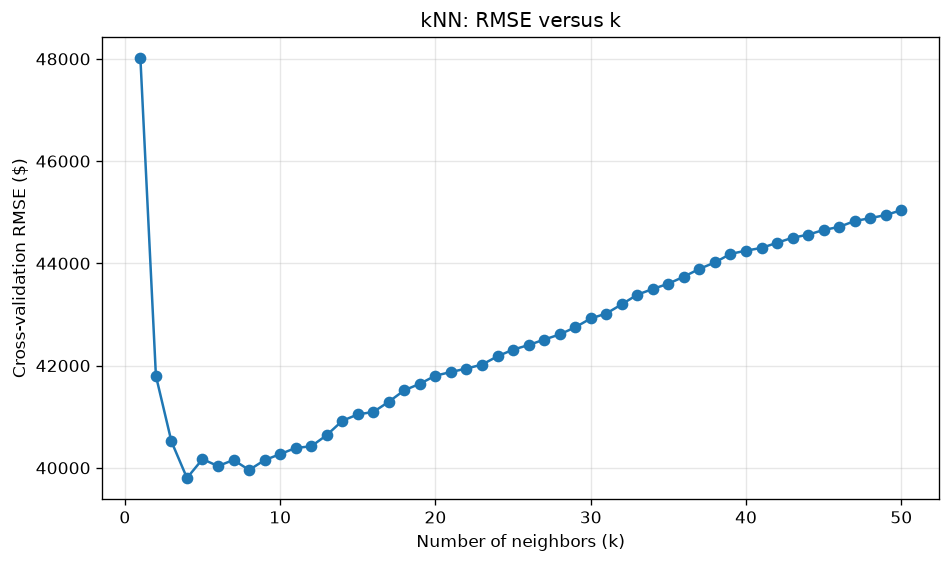

Best k: 4
Lowest CV RMSE: $39,800.82


In [5]:
original_features = feature_sets['Original']
k_values = list(range(1, 51))
search2 = GridSearchCV(make_model(KNeighborsRegressor(metric='euclidean')), {'model__n_neighbors': k_values}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1)
search2.fit(ames_train[original_features], y_train)
results2 = pd.DataFrame(search2.cv_results_)
results2['k'] = results2['param_model__n_neighbors'].astype(int)
results2['CV RMSE'] = -results2['mean_test_score']
results2 = results2.sort_values('k')

plt.figure(figsize=(9, 5))
plt.plot(results2['k'], results2['CV RMSE'], marker='o')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Cross-validation RMSE ($)')
plt.title('kNN: RMSE versus k')
plt.grid(alpha=0.3)
plt.show()

print('Best k:', search2.best_params_['model__n_neighbors'])
print(f'Lowest CV RMSE: ${-search2.best_score_:,.2f}')

3\. $k$-nearest neighbors relies on distance and we know there are different distance metrics. Repeat the previous part and use grid search to iterate over both (1) `n_neighbors` and (2) `metric`, which can be `"euclidean"` or `"manhattan"` (see the the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)). Compare the results to the previous part. (Hint: recall the note in the pre-class notebook about grid search conventions for refering to steps in the pipeline.)

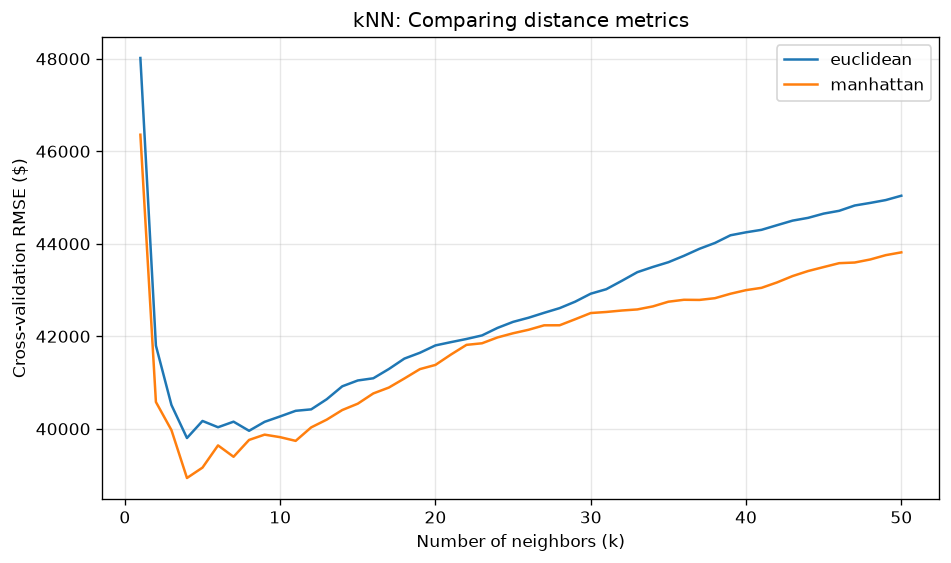

Best parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 4}
Question 2 CV RMSE: $39,800.82
Question 3 CV RMSE: $38,936.52
RMSE reduction from tuning the metric: $864.30


In [6]:
search3 = GridSearchCV(make_model(KNeighborsRegressor()), {'model__n_neighbors': k_values, 'model__metric': ['euclidean', 'manhattan']}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1)
search3.fit(ames_train[original_features], y_train)
results3 = pd.DataFrame(search3.cv_results_)
results3['k'] = results3['param_model__n_neighbors'].astype(int)
results3['metric'] = results3['param_model__metric']
results3['CV RMSE'] = -results3['mean_test_score']

plt.figure(figsize=(9, 5))
for metric in ['euclidean', 'manhattan']:
    subset = results3[results3['metric'] == metric].sort_values('k')
    plt.plot(subset['k'], subset['CV RMSE'], label=metric)
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Cross-validation RMSE ($)')
plt.title('kNN: Comparing distance metrics')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print('Best parameters:', search3.best_params_)
print(f'Question 2 CV RMSE: ${-search2.best_score_:,.2f}')
print(f'Question 3 CV RMSE: ${-search3.best_score_:,.2f}')
improvement = (-search2.best_score_) - (-search3.best_score_)
print(f'RMSE reduction from tuning the metric: ${improvement:,.2f}')

4\. Combine elements of the previous parts and fit what you think will be the best $k$-nearest neighbors model. Specify which features you are using, the value of $k$, and the distance metric. Estimate the test error. (In 2-3 you used the specified set of features. Now you can combine elements of 2-3 with the features you chose in part 1, or other sets of features, as well as investigating other parameter choices.)

Note: Look at the [`KNeighborsRegressor` documentation](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html) for a full list of parameters. You might consider tuning `n_neighbors`, `metric` (or `p`), and/or `weights`. You could also try other elements like scaling too.

In [7]:
param_grid = {'model__n_neighbors': [3, 5, 7, 10, 15, 20, 30], 'model__metric': ['euclidean', 'manhattan'], 'model__weights': ['uniform', 'distance']}
searches4 = {}
rows = []
for name, features in feature_sets.items():
    search = GridSearchCV(make_model(KNeighborsRegressor()), param_grid, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1)
    search.fit(ames_train[features], y_train)
    searches4[name] = search
    rows.append({'Feature set': name, 'CV RMSE': -search.best_score_})
part4 = pd.DataFrame(rows).sort_values('CV RMSE')
best_set = part4.iloc[0]['Feature set']
best_features = feature_sets[best_set]
best_knn = searches4[best_set].best_estimator_
knn_test_rmse = np.sqrt(mean_squared_error(y_test, best_knn.predict(ames_test[best_features])))
print((part4).to_string())
print('Selected feature set:', best_set)
print('Features:', best_features)
print('Best parameters:', searches4[best_set].best_params_)
print(f'Selected model CV RMSE: ${-searches4[best_set].best_score_:,.2f}')
print(f'Held-out test RMSE: ${knn_test_rmse:,.2f}')

             Feature set       CV RMSE
4               Expanded  28669.154865
3  Size, quality, garage  29689.852405
2     Size, quality, age  31959.679481
1       Size and quality  33155.124162
0               Original  38291.888164
Selected feature set: Expanded
Features: ['Gr Liv Area', 'Overall Qual', 'Year Built', 'Year Remod/Add', 'Garage Cars', 'Total Bsmt SF', 'Full Bath', 'Neighborhood', 'Kitchen Qual']
Best parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 10, 'model__weights': 'distance'}
Selected model CV RMSE: $28,669.15
Held-out test RMSE: $30,910.71


5\. Now fit a linear regression model using the same features that you used in the previous part. Estimate the test error. How does the test error for linear regression compare to the kNN model?


In [8]:
linear_model = make_model(LinearRegression())
linear_scores = cross_val_score(linear_model, ames_train[best_features], y_train, cv=cv, scoring='neg_root_mean_squared_error')
linear_model.fit(ames_train[best_features], y_train)
linear_test_rmse = np.sqrt(mean_squared_error(y_test, linear_model.predict(ames_test[best_features])))
comparison = pd.DataFrame({
    'Model': ['Tuned kNN', 'Linear regression'],
    'CV RMSE': [-searches4[best_set].best_score_, -linear_scores.mean()],
    'Test RMSE': [knn_test_rmse, linear_test_rmse]
})
print((comparison).to_string())

difference = abs(knn_test_rmse - linear_test_rmse)
if linear_test_rmse < knn_test_rmse:
    print(f'Linear regression has the lower test RMSE by ${difference:,.2f}.')
elif knn_test_rmse < linear_test_rmse:
    print(f'Tuned kNN has the lower test RMSE by ${difference:,.2f}.')
else:
    print('The models have equal test RMSE.')

               Model       CV RMSE     Test RMSE
0          Tuned kNN  28669.154865  30910.714286
1  Linear regression  32662.192304  32195.069385
Tuned kNN has the lower test RMSE by $1,284.36.


## Loans Data

The loans data set represents thousands of loans made through the Lending Club platform, which is a platform that allows individuals to lend to other individuals. Of course, not all loans are created equal. Someone who is a essentially a sure bet to pay back a loan will have an easier time getting a loan with a low interest rate than someone who appears to be riskier. And for people who are very risky? They may not even get a loan offer, or they may not have accepted the loan offer due to a high interest rate. It is important to keep that last part in mind, since this dataset only represents loans actually made, i.e. do not mistake this data for loan applications!

[Some information about the data set is here](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). There are also some related exercises in this [OpenIntro textbook](https://openintro-ims.netlify.app/inf-model-mlr.html).

**Our goal will be to develop a regression model for predicting `interest_rate`.**

We will have a competition to see who can come up with the model with the smallest test RMSE. Fit several models and try to find the smallest test RMSE. When you think you have a good one, share your model and its test RMSE. Then see what other people have done; can you do even better?

Note: when you are consider features to include, you might want to consider transformations of the variables.

You should use `GridSearchCV` to tune at least one parameter.

Note: you should do some exploration of the data first before you start fitting models.

In [9]:
df = pd.read_csv("https://raw.githubusercontent.com/kevindavisross/data301/refs/heads/main/data/loans_full_schema.csv")

print(df.head().to_string())

   Unnamed: 0                emp_title  emp_length state homeownership  annual_income  verified_income  debt_to_income  annual_income_joint verification_income_joint  debt_to_income_joint  delinq_2y  months_since_last_delinq  earliest_credit_line  inquiries_last_12m  total_credit_lines  open_credit_lines  total_credit_limit  total_credit_utilized  num_collections_last_12m  num_historical_failed_to_pay  months_since_90d_late  current_accounts_delinq  total_collection_amount_ever  current_installment_accounts  accounts_opened_24m  months_since_last_credit_inquiry  num_satisfactory_accounts  num_accounts_120d_past_due  num_accounts_30d_past_due  num_active_debit_accounts  total_debit_limit  num_total_cc_accounts  num_open_cc_accounts  num_cc_carrying_balance  num_mort_accounts  account_never_delinq_percent  tax_liens  public_record_bankrupt        loan_purpose application_type  loan_amount  term  interest_rate  installment grade sub_grade issue_month loan_status initial_listing_status dis

                               count unique                 top  freq           mean            std     min      25%       50%       75%        max
annual_income                 8000.0    NaN                 NaN   NaN   79214.223659   65308.295377     0.0  45000.0   65000.0   95000.0  2300000.0
debt_to_income                7981.0    NaN                 NaN   NaN      19.229881      14.156587     0.0    11.04      17.6     24.96     437.61
emp_length                    7358.0    NaN                 NaN   NaN       5.930688       3.696128     0.0      2.0       6.0      10.0       10.0
homeownership                   8000      3            MORTGAGE  3828            NaN            NaN     NaN      NaN       NaN       NaN        NaN
verified_income                 8000      3     Source Verified  3338            NaN            NaN     NaN      NaN       NaN       NaN        NaN
loan_purpose                    8000     12  debt_consolidation  4084            NaN            NaN     NaN     

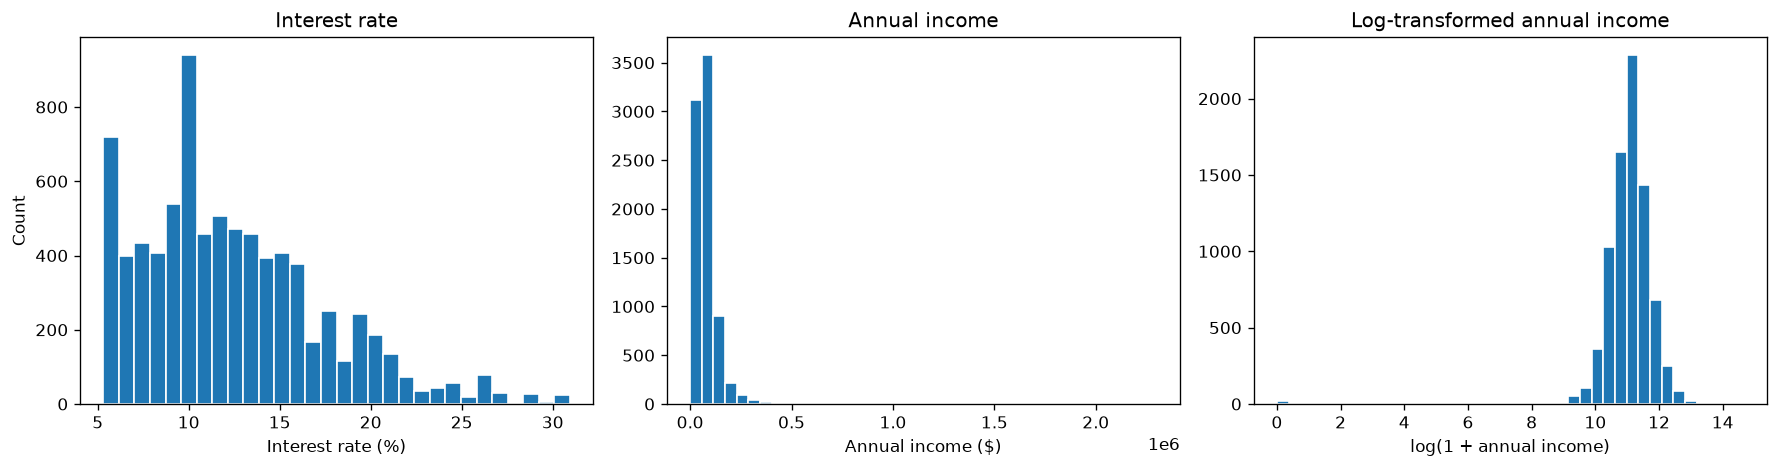

Correlations with interest rate:
term                            0.352690
debt_to_income                  0.147757
total_credit_limit             -0.138175
inquiries_last_12m              0.130744
account_never_delinq_percent   -0.122058
annual_income                  -0.106687
delinq_2y                       0.092282
loan_amount                     0.058945
public_record_bankrupt          0.049698
total_credit_lines             -0.044580
emp_length                     -0.031029
total_credit_utilized           0.023268
open_credit_lines              -0.013235
               Model   CV RMSE
1  Linear regression  4.194439
2          Tuned kNN  4.279782
0      Mean baseline  4.988937
Best kNN parameters: {'model__metric': 'manhattan', 'model__n_neighbors': 40, 'model__weights': 'distance'}
Selected model: Linear regression
Features: ['annual_income', 'debt_to_income', 'emp_length', 'homeownership', 'verified_income', 'loan_purpose', 'application_type', 'loan_amount', 'term', 'delinq_2y', 

In [10]:
loan_features = ['annual_income', 'debt_to_income', 'emp_length', 'homeownership', 'verified_income', 'loan_purpose', 'application_type', 'loan_amount', 'term', 'delinq_2y', 'inquiries_last_12m', 'total_credit_lines', 'open_credit_lines', 'total_credit_limit', 'total_credit_utilized', 'account_never_delinq_percent', 'public_record_bankrupt']
loans_train, loans_test = train_test_split(df.dropna(subset=['interest_rate']), test_size=0.20, random_state=5544)
print((loans_train[loan_features + ['interest_rate']].describe(include='all').T).to_string())
print('Missing values:')
print((loans_train[loan_features].isna().sum().sort_values(ascending=False)).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(loans_train['interest_rate'], bins=30, edgecolor='white')
axes[0].set_title('Interest rate')
axes[0].set_xlabel('Interest rate (%)')
axes[0].set_ylabel('Count')
axes[1].hist(loans_train['annual_income'].dropna(), bins=40, edgecolor='white')
axes[1].set_title('Annual income')
axes[1].set_xlabel('Annual income ($)')
axes[2].hist(np.log1p(loans_train['annual_income'].dropna()), bins=40, edgecolor='white')
axes[2].set_title('Log-transformed annual income')
axes[2].set_xlabel('log(1 + annual income)')
plt.tight_layout()
plt.show()

numeric_data = loans_train[loan_features + ['interest_rate']].select_dtypes(include=np.number)
correlations = numeric_data.corr()['interest_rate'].drop('interest_rate')
print('Correlations with interest rate:')
print((correlations.sort_values(key=lambda values: values.abs(), ascending=False)).to_string())

X_loan_train = loans_train[loan_features].copy()
X_loan_test = loans_test[loan_features].copy()
for col in ['annual_income', 'loan_amount', 'total_credit_limit', 'total_credit_utilized']:
    X_loan_train[col] = np.log1p(X_loan_train[col])
    X_loan_test[col] = np.log1p(X_loan_test[col])
y_loan_train = loans_train['interest_rate']
y_loan_test = loans_test['interest_rate']
loan_models = {'Mean baseline': make_model(DummyRegressor()), 'Linear regression': make_model(LinearRegression())}
loan_rows = []
for name, model in loan_models.items():
    scores = cross_val_score(model, X_loan_train, y_loan_train, cv=cv, scoring='neg_root_mean_squared_error')
    loan_rows.append({'Model': name, 'CV RMSE': -scores.mean()})
loan_search = GridSearchCV(make_model(KNeighborsRegressor()), {'model__n_neighbors': [5, 10, 20, 40, 80], 'model__metric': ['euclidean', 'manhattan'], 'model__weights': ['uniform', 'distance']}, scoring='neg_root_mean_squared_error', cv=cv, n_jobs=1)
loan_search.fit(X_loan_train, y_loan_train)
loan_models['Tuned kNN'] = loan_search.best_estimator_
loan_rows.append({'Model': 'Tuned kNN', 'CV RMSE': -loan_search.best_score_})
loan_results = pd.DataFrame(loan_rows).sort_values('CV RMSE')
loan_winner = loan_results.iloc[0]['Model']
final_loan_model = loan_models[loan_winner]
final_loan_model.fit(X_loan_train, y_loan_train)
loan_test_rmse = np.sqrt(mean_squared_error(y_loan_test, final_loan_model.predict(X_loan_test)))
print((loan_results).to_string())
print('Best kNN parameters:', loan_search.best_params_)
print('Selected model:', loan_winner)
print('Features:', loan_features)
print('Log-transformed features:', ['annual_income', 'loan_amount', 'total_credit_limit', 'total_credit_utilized'])
print(f"Selected model CV RMSE: {loan_results.iloc[0]['CV RMSE']:.3f} percentage points")
print(f'Held-out test RMSE: {loan_test_rmse:.3f} percentage points')